# H₂・CO 化学の反応収支の検証

H II 領域・H₂・CO・ダスト・宇宙線・軟X線・H–O 電荷交換をすべて有効にした設定で、EQCLib の化学平衡を確認します。銀河シミュレーションで使う設定と同じです。

各平衡状態について、H₂ と CO の生成・消滅、電荷交換を含む H と O の電離・再結合の反応量を、公開されている反応率関数から独立に計算し直して比べます。最終的な H₂ 量で CO を解き直したときの変化も確認します。

再計算するには EQCLib のルートで `make -C test co` を実行し、下のセルを上から実行します。PNG だけが必要な場合は `make -C test co-plot` を使います。計算条件と CSV の詳細は [README](../README.md) の「H₂・CO 化学の検証計算と描画」 にあります。

In [1]:
%matplotlib inline

import sys
from pathlib import Path

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np

cwd = Path.cwd()
repo_root = next(
    (directory for directory in (cwd, *cwd.parents)
     if (directory / "plot" / "PlotCOChemistry.ipynb").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("EQCLib のリポジトリ内からノートブックを実行してください。")

run_dir = repo_root / "test" / "out" / "co"

plot_dir = str(repo_root / "plot")
if plot_dir not in sys.path:
    sys.path.insert(0, plot_dir)

from plot_style import PLOT_STYLE
from plot_co_chemistry import (BALANCE_LIMIT, load_results, plot_abundances, plot_balances,
                               plot_column_scan, plot_fluxes)

try:
    grid, scan = load_results(run_dir)
except FileNotFoundError as error:
    raise FileNotFoundError(
        f"{run_dir} に必要な CSV がありません。make -C test co を実行してください。"
    ) from error

print(f"密度・温度・電離光子束の格子 {len(grid)} 条件、柱密度走査 {len(scan)} 点")

密度・温度・電離光子束の格子 252 条件、柱密度走査 164 点


## 反応収支

縦軸は各反応の生成側と消滅側の相対差 $|F_+-F_-|/\max(F_+,F_-)$ です。破線は試験の判定値 $10^{-6}$ で、`make -C test co` はどれか一つでも超えると失敗します。化学平衡は精度 $10^{-9}$ で解いています。

- H₂：ダスト表面での生成と、遮蔽を含む光解離・衝突解離
- CO：C⁺ と H₂ からの生成（Glover & Clark 2012）と、H₂・CO 遮蔽を含む光解離
- H：電荷交換を含む電離と再結合
- 最終的な H₂ 量で CO を解き直したときの CO の相対変化

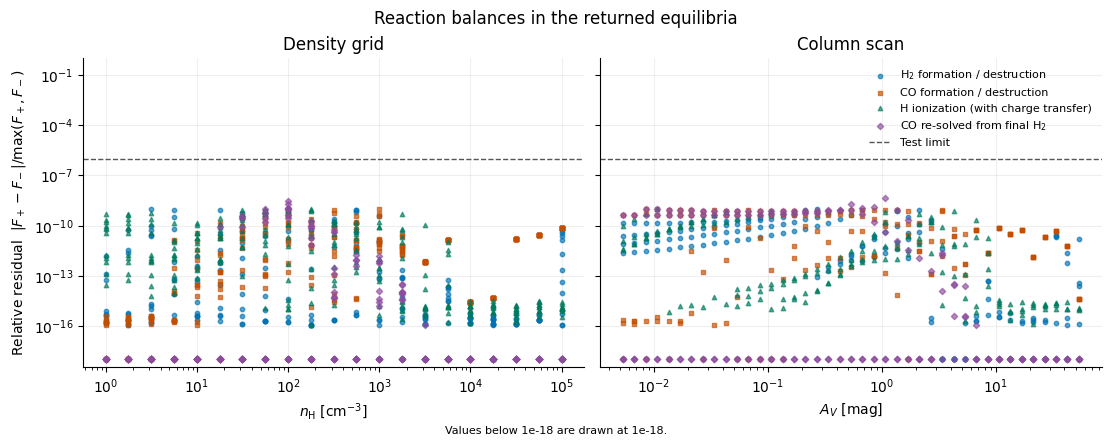

| 収支 | 格子の最大 | 柱密度走査の最大 |
|---|---:|---:|
| H₂ の生成・消滅 | 9.6e-10 | 9.3e-10 |
| CO の生成・消滅 | 9.4e-10 | 9.7e-10 |
| H の電離・再結合（電荷交換を含む） | 9.4e-10 | 9.8e-10 |
| O I ⇄ O II（電荷交換を含む） | 6.6e-16 | 4.1e-16 |
| O II ⇄ O III（電荷交換を含む） | 3.9e-16 | 0.0e+00 |
| 最終 H₂ で解き直した CO の変化 | 2.9e-09 | 4.7e-09 |

最大の相対差 4.7e-09（判定値 1e-06）


In [2]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_balances(grid, scan)
    display(fig)
    plt.close(fig)

fields = {
    "residual_H2": "H₂ の生成・消滅",
    "residual_CO": "CO の生成・消滅",
    "residual_H": "H の電離・再結合（電荷交換を含む）",
    "residual_OI": "O I ⇄ O II（電荷交換を含む）",
    "residual_OII": "O II ⇄ O III（電荷交換を含む）",
    "CO_consistency": "最終 H₂ で解き直した CO の変化",
}
rows = ["| 収支 | 格子の最大 | 柱密度走査の最大 |", "|---|---:|---:|"]
for field, label in fields.items():
    rows.append(f"| {label} | {grid[field].max():.1e} | {scan[field].max():.1e} |")
display(Markdown("\n".join(rows)))
worst = max(max(grid[f].max(), scan[f].max()) for f in fields)
print(f"最大の相対差 {worst:.1e}（判定値 {BALANCE_LIMIT:g}）")

## 密度に対する分子の割合

$G_0=1.7$、全柱密度 $N_{\rm H}=2\times10^{21}(n_{\rm H}/100)^{1/2}$ cm⁻² とし、密度とともに減光も増える条件です。左から、電離光子なし、$\log_{10}U=-5$、$\log_{10}U=-3$ です。

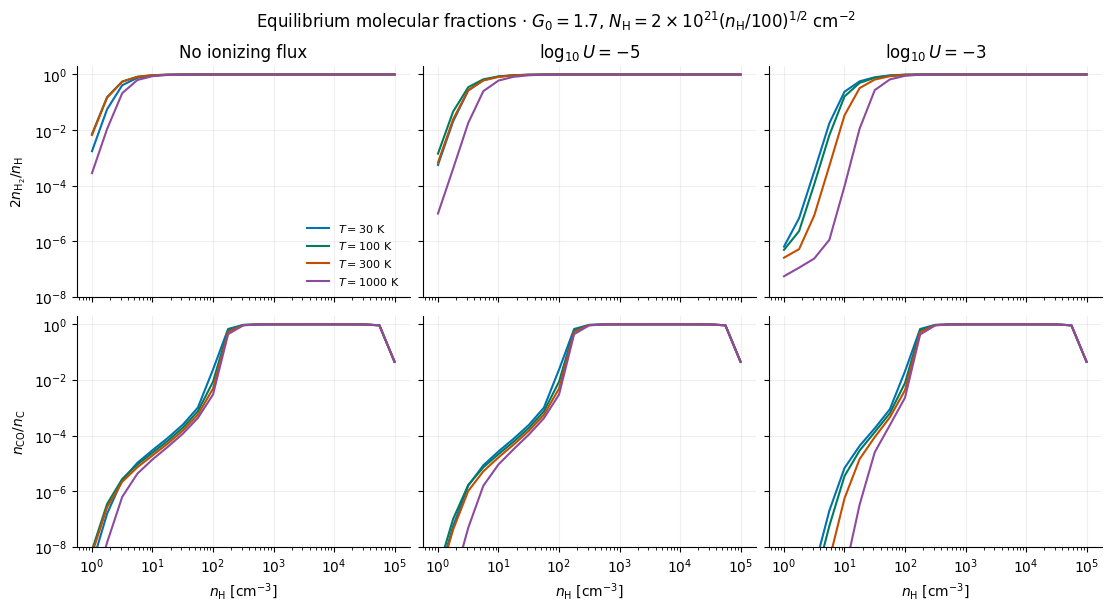

In [3]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_abundances(grid)
    display(fig)
    plt.close(fig)

## 柱密度に対する H/H₂ と C⁺/C/CO の遷移

電離光子のない光解離領域を想定し、$T=30$ K で全柱密度を $10^{19}$〜$10^{23}$ cm⁻² まで変えます。各点は一つ前の柱密度の解から始めます。$n_{\rm H}/G_0$ が同じ条件は同じ曲線になります。

**モデルの適用範囲**：CO 化学は Keto & Caselli (2008) の平衡モデル（Glover & Clark 2012 の KC08e）で、C⁺ + H₂ → CO、CO の光解離、C の光電離の3反応だけを含みます。宇宙線による反応と C⁺ の再結合はありません。平衡では $x_{\rm C}/x_{\rm CO}=\Gamma_{\rm CO}/\Gamma_{\rm C}$ で、ダスト減光の指数が CO（2.5）と C（3.0）で異なるため、この比は $e^{0.5A_V}$ で増えます。そのため $A_V\approx3$〜$10$ では CO が炭素の 99% 以上を占めますが、$A_V\gtrsim25$ では C I が主になります。実際の高密度コアでは CO が残るので、この領域の C・CO の存在比は信頼できません。詳しくは README の「CO モデルの適用範囲」を参照してください。反応収支の検証は、この制限とは独立に成り立っています。

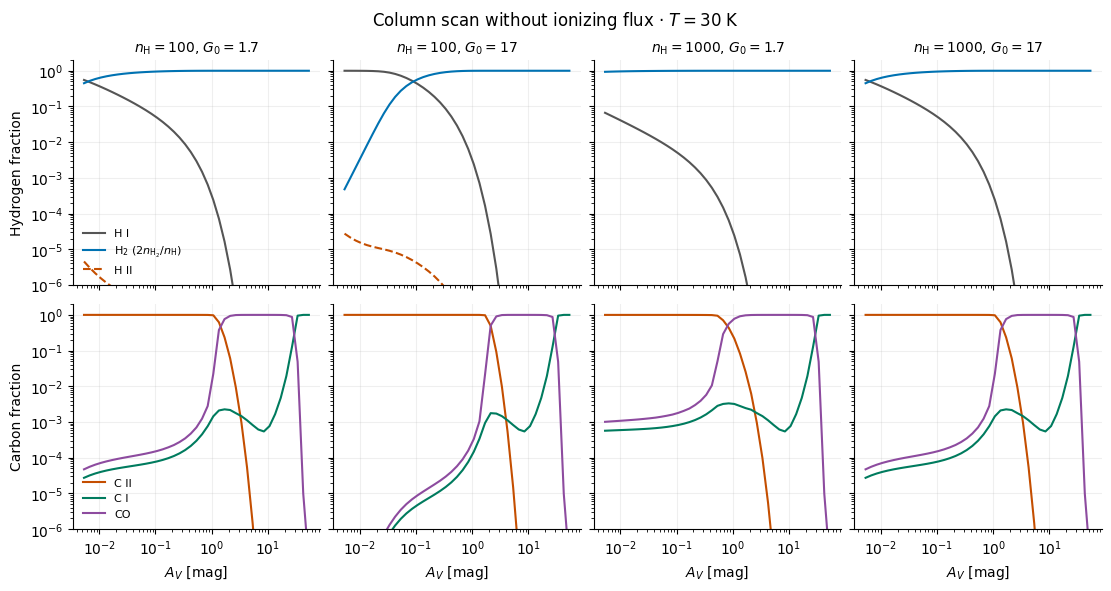

In [4]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_column_scan(scan)
    display(fig)
    plt.close(fig)

## 生成と消滅の反応量

$T=30$ K、電離光子なしの格子で、H₂ と CO の生成と消滅を水素核密度の二乗で規格化して示します。どの密度でも両者が重なっていることが、反応平衡を表します。高密度で反応量が急に小さくなるのは、ダストによる減光で光解離と炭素の光電離が抑えられるためです。

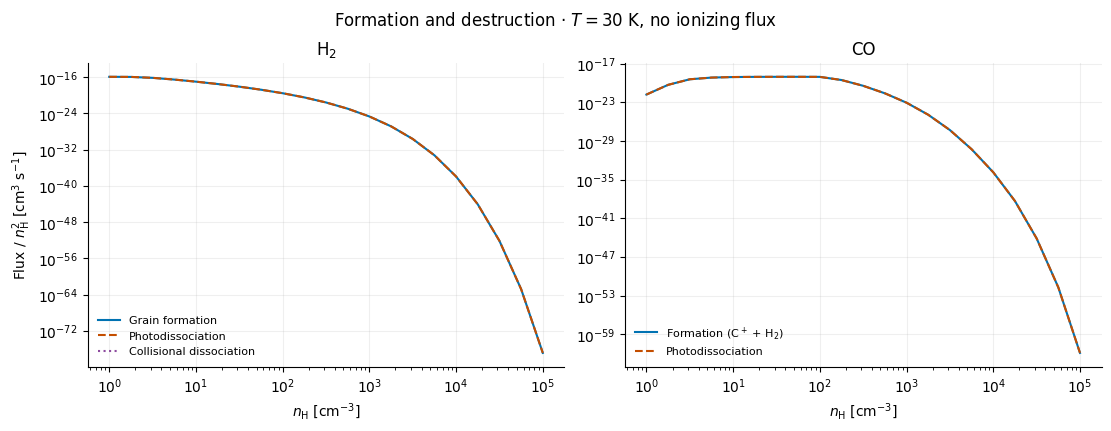

In [5]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_fluxes(grid)
    display(fig)
    plt.close(fig)

### 代表条件の数値

$n_{\rm H}=100$ cm⁻³、$T=30$ K、電離光子なしの平衡状態です。存在比は各元素の総数に対する割合です。

In [6]:
row = grid[(grid["nH"] == 100) & (grid["T"] == 30) & np.isneginf(grid["log_U"])][0]
table = ["| 量 | 値 |", "|---|---:|"]
for field, label, fmt in (
    ("Av", "減光 A_V [mag]", ".2f"),
    ("H2", "2n(H₂)/n_H", ".4f"), ("HI", "H I", ".2e"), ("HII", "H II", ".2e"),
    ("CO", "CO/C", ".4f"), ("CI", "C I", ".2e"), ("CII", "C II", ".2e"),
    ("OI", "O I", ".4f"), ("OII", "O II", ".2e"),
    ("H2_formation", "H₂ 生成 [cm⁻³ s⁻¹]", ".3e"), ("H2_photodissociation", "H₂ 光解離 [cm⁻³ s⁻¹]", ".3e"),
    ("CO_formation", "CO 生成 [cm⁻³ s⁻¹]", ".3e"), ("CO_photodissociation", "CO 光解離 [cm⁻³ s⁻¹]", ".3e"),
):
    table.append(f"| {label} | {row[field]:{fmt}} |")
display(Markdown("\n".join(table)))

| 量 | 値 |
|---|---:|
| 減光 A_V [mag] | 1.07 |
| 2n(H₂)/n_H | 0.9998 |
| H I | 2.37e-04 |
| H II | 6.37e-09 |
| CO/C | 0.0236 |
| C I | 1.45e-03 |
| C II | 9.75e-01 |
| O I | 0.9844 |
| O II | 4.96e-06 |
| H₂ 生成 [cm⁻³ s⁻¹] | 2.889e-16 |
| H₂ 光解離 [cm⁻³ s⁻¹] | 2.889e-16 |
| CO 生成 [cm⁻³ s⁻¹] | 9.331e-16 |
| CO 光解離 [cm⁻³ s⁻¹] | 9.331e-16 |